# HCP task-fMRI 전처리와 조건별 β-map 추출

HCP 피험자 한 명의 원시 fMRI를 불러와 시간·움직임 보정과 공간 평활화를 적용하고, GLM으로 과제 조건별 β-map을 추출한 기록이다. 영상 파일과 자극 시점을 연결하는 과정부터 모델 입력으로 저장하는 단계까지 다룬다.

## 프로젝트 안에서의 역할

전체 프로젝트는 원시 데이터 전처리 실습과 제공된 β-map을 이용한 모델 학습으로 나뉜다.

| 노트북 | 내용 |
|---|---|
| **01 · HCP preprocessing — 현재 문서** | 원시 HCP 영상에서 조건별 β-map 추출 |
| 02 · NSD preprocessing | 원시 NSD 영상 처리 및 이미지·캡션 연결 |
| 03 · HCP classification | 제공된 HCP β-map으로 19개 과제 조건 분류 |
| 04 · NSD caption decoding | 분류 인코더를 GPT-2에 연결한 캡션 생성 |

**이 노트북의 산출물은 분류 모델의 주 학습 데이터로 사용하지 않았다.** 모델 학습에는 수업에서 별도로 제공한 β-map을 사용했고, 여기서 만든 데이터는 학습 후 추가 입력 테스트에 사용했다.

## 실행 전 확인

- 원시 HCP 데이터와 EV 파일은 별도로 준비해야 한다. 아래 코드는 당시 사용한 로컬 폴더 경로를 포함한다.
- `hcp_data`와 `subject_id`를 데이터 위치에 맞게 설정하고 위에서부터 실행한다.
- 4D 영상 여러 개를 메모리에 보관하고 프레임별 registration을 수행하므로 시간과 메모리가 많이 필요하다.
- 아래 그림과 로그는 기존 실행 기록이다. 문서 정리 과정에서 전처리를 다시 실행하지 않았다.

먼저 필요한 라이브러리를 설치하고 불러온다. 설치·import 셀에는 후속 모델 학습 노트북과 공유하던 항목도 남아 있다.


In [ ]:
!pip install nilearn nibabel
!pip install antspyx
!pip install transformers evaluate rouge_score h5py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 73.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.4/22.4 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 12.6 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.3 MB/s eta 0:00:00
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=41ef39ddb0b2ff9dfbf3ca9807a7fb7c26ca1e2bde9ea34bf9d8114e7cb46715
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
Successfully built rouge_score


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path
import importlib.util
import nibabel as nib
from nilearn import image, plotting
from nilearn import datasets
from nilearn.maskers import NiftiMasker
from nilearn.glm.first_level import (
        FirstLevelModel,
        make_first_level_design_matrix,
    )
from nilearn.masking import apply_mask
from sklearn.model_selection import train_test_split
from scipy.spatial.transform import Rotation
import ants
import random
import json

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.manifold import TSNE
from transformers import AutoTokenizer, AutoModelForCausalLM
import evaluate
import h5py
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer


## 1. 입력 데이터와 처리 목표

대상은 HCP 피험자 `100206`의 task-fMRI다. 입력 영상은 공간 3축과 시간축을 가진 `(x, y, z, t)` 형태의 NIfTI 파일이며, TR은 **0.72초**다.

```text
<피험자>/unprocessed/3T/<task>/
├── <피험자>_3T_<task>.nii.gz
└── LINKED_DATA/EPRIME/EVs/
    └── <condition>.txt
```

EV(Explanatory Variables) 파일은 자극의 시작 시점(onset), 지속 시간(duration), amplitude를 담는다. 이 코드에서는 onset과 duration, 파일명에서 얻은 조건명을 사용해 GLM 이벤트 테이블을 구성한다. amplitude 값은 읽지만 모델 입력에는 반영하지 않는다.

목표는 연속된 BOLD 시계열을 **조건별 반응 크기를 나타내는 β-map**으로 바꾸는 것이다. 조건마다 3D map을 구한 뒤 마스크 안의 voxel을 1차원 벡터로 추출한다.


## 2. 처리 흐름과 실행 결과 요약

```text
4D NIfTI + EV 파일
 → Slice-timing correction
 → 프레임별 rigid-body motion correction
 → 공간 평활화 (FWHM 6 mm)
 → run별 first-level GLM
 → 조건별 effect-size map
 → 마스킹 및 1차원 벡터 추출
 → β-map과 라벨을 NPZ로 저장
```

| 항목 | 기존 실행 결과 |
|---|---|
| 피험자 | `100206` |
| 처리 run 수 | 12 |
| TR | 0.72초 |
| 추출 조건 수 | 15 |
| 조건별 β-map 수 | LR/RL run에서 각각 1개, 총 2개 |
| 전체 β-map 수 | 30 |
| map당 voxel 수 | 182,453 |
| 집계 배열 형태 | `(30, 182453)` |

추출된 조건은 `fear`, `neut`, `loss`, `win`, `math`, `story`, `lf`, `lh`, `rf`, `rh`, `t`, `match`, `relation`, `mental`, `rnd`다. 후보 라벨 중 `body`, `faces`, `places`, `tools`, `rest`는 이번 처리 결과에 포함되지 않았다.

### 이번 실행에서 생략한 단계

메모리 제약으로 구조영상과의 coregistration 및 표준공간 정규화를 생략했다. 마스크는 Nilearn의 MNI152 brain mask를 기능영상 격자로 resampling해 사용했다. 격자를 맞추는 resampling과 해부학적 위치를 맞추는 registration은 다른 작업이므로, 이 결과는 표준공간 정합까지 완료한 데이터와 구분한다.

이하에서는 보정 함수, 입력 구성, GLM, 결과 저장 순서로 구현 내용을 살펴본다.


In [ ]:
def load_slice_timing_from_json(json_path):
    if not json_path.exists():
        return None
    with open(json_path, "r", encoding="utf-8") as f:
        meta_json = json.load(f)
    return meta_json.get("SliceTiming", None)

def slice_timing_correct_4d(data_4d, tr, slice_timing=None):
    nx, ny, nz, nt = data_4d.shape
    t = np.arange(nt) * tr

    if slice_timing is None:
        # SliceTiming이 없으면 z축 순차 획득을 가정한다.
        slice_timing = np.linspace(0, tr - tr / nz, nz)
    else:
        slice_timing = np.asarray(slice_timing, dtype=float)
        if len(slice_timing) != nz:
            raise ValueError("SliceTiming length must equal number of slices (z dimension).")

    target_time = float(np.median(slice_timing))
    corrected = np.empty_like(data_4d, dtype=np.float32)

    for z in range(nz):
        dt = target_time - slice_timing[z]
        source_t = np.clip(t - dt, t.min(), t.max())
        slab = data_4d[:, :, z, :]
        corrected[:, :, z, :] = np.apply_along_axis(lambda y: np.interp(source_t, t, y), axis=-1, arr=slab)

    return corrected

def compute_fd_from_motion(motion_df, radius_mm=50.0):
    rot_cols = ["rot_x", "rot_y", "rot_z"]
    trans_cols = ["trans_x", "trans_y", "trans_z"]

    motion_diff = motion_df[trans_cols + rot_cols].diff().fillna(0)
    rot_mm = motion_diff[rot_cols].abs() * radius_mm
    trans_mm = motion_diff[trans_cols].abs()
    fd = trans_mm.sum(axis=1) + rot_mm.sum(axis=1)
    return fd

def ants_rigid_motion_correction(data_4d, affine):
    spacing = tuple(float(s) for s in nib.affines.voxel_sizes(affine)[:3])
    direction = np.eye(3)
    origin = (0.0, 0.0, 0.0)
    nt = data_4d.shape[3]

    def to_ants_image(volume):
        return ants.from_numpy(volume.astype(np.float32), spacing=spacing, origin=origin, direction=direction)

    ref_img = to_ants_image(data_4d[:, :, :, 0])
    corrected = np.empty_like(data_4d, dtype=np.float32)
    motion_rows = []

    for t_idx in range(nt):
        moving_img = to_ants_image(data_4d[:, :, :, t_idx])
        reg = ants.registration(
            fixed=ref_img,
            moving=moving_img,
            type_of_transform="Rigid",
        )
        corrected[:, :, :, t_idx] = reg["warpedmovout"].numpy()

        tx = ants.read_transform(reg["fwdtransforms"][0])
        params = np.asarray(tx.parameters, dtype=float)
        rotation_matrix = params[:9].reshape(3, 3)
        translation = params[9:12]
        euler_xyz = Rotation.from_matrix(rotation_matrix).as_euler("xyz", degrees=False)

        motion_rows.append(
            {
                "trans_x": float(translation[0]),
                "trans_y": float(translation[1]),
                "trans_z": float(translation[2]),
                "rot_x": float(euler_xyz[0]),
                "rot_y": float(euler_xyz[1]),
                "rot_z": float(euler_xyz[2]),
            }
        )

    return corrected, pd.DataFrame(motion_rows), "ANTs rigid-body registration"


### 2.1 시간 보정과 움직임 보정

위 함수들은 영상 전처리에서 반복 사용하는 작업을 나눈 것이다.

- **`load_slice_timing_from_json`**: 영상과 함께 제공된 JSON에서 `SliceTiming`을 읽는다. 파일이 없으면 `None`을 반환한다.
- **`slice_timing_correct_4d`**: slice별 시계열을 선형 보간해 acquisition time의 중앙값에 맞춘다. 메타데이터가 없으면 z축 순차 획득을 가정한 timing을 사용한다. 이 fallback은 실제 획득 순서를 확인한 설정과 구분할 필요가 있다.
- **`ants_rigid_motion_correction`**: 첫 번째 volume을 기준으로 나머지 volume을 rigid registration한다. 보정 영상과 함께 3축 이동·3축 회전 파라미터를 반환한다.
- **`compute_fd_from_motion`**: 연속 프레임의 이동·회전 변화량을 합산한다. 회전은 반경 50 mm를 사용해 거리로 환산한다.

움직임 파라미터와 FD는 각 run의 처리 중 계산한다. 다만 현재 구현에서는 이를 GLM의 confound로 전달하거나 별도 파일로 저장하지 않는다.


In [ ]:
def load_event(ev_dir) :
    events_list = []

    for ev_file in os.listdir(ev_dir):

        if not ev_file.endswith('.txt') or ev_file == 'Sync.txt':
            continue

        condition = ev_file.replace('.txt', '')
        if condition not in ['fear', 'neut', 'loss', 'win', 'math', 'story', 'lf', 'lh', 'rf', 'rh', 't', 'match', 'relation', 'mental', 'rnd', 'body', 'faces', 'places', 'tools', 'rest'] :
            continue
        ev_data = np.loadtxt(f"{ev_dir}/{ev_file}")

        if ev_data.ndim == 1:
            ev_data = [ev_data]

        if len(ev_data[0]) == 0:
            continue

        for onset, duration, amp in ev_data:
            events_list.append({
                "onset": onset,
                "duration": duration,
                "trial_type": condition
            })
    events_df = pd.DataFrame(events_list)
    return events_df

def load_image(task_name) :
    nii_path = f"{hcp_data}/{subject_id}/unprocessed/3T/{task_name}/{subject_id}_3T_{task_name}.nii.gz"
    ev_dir = f"{hcp_data}/{subject_id}/unprocessed/3T/{task_name}/LINKED_DATA/EPRIME/EVs"

    event = load_event(ev_dir)
    if event.empty:
        return None, None

    func_raw_img = nib.load(str(nii_path))
    tr = func_raw_img.header.get_zooms()[-1]

    func_raw_data = func_raw_img.get_fdata(dtype=np.float32)
    FUNC_JSON = Path(nii_path.replace(".nii.gz", ".json"))
    slice_timing = load_slice_timing_from_json(FUNC_JSON)
    corrected_data = slice_timing_correct_4d(func_raw_data, tr, slice_timing=slice_timing)

    mc_data, motion_df, motion_method = ants_rigid_motion_correction(corrected_data, func_raw_img.affine)
    motion_df["framewise_displacement"] = compute_fd_from_motion(motion_df)
    func_mc_img = nib.Nifti1Image(mc_data, func_raw_img.affine, func_raw_img.header)

    smooth_source = func_mc_img
    smooth_img = image.smooth_img(smooth_source, fwhm=SMOOTH_FWHM)

    result = smooth_img

    n_frames = result.shape[3]

    print("Image shape:", result.shape)
    print("TR:", tr)
    return result, event

hcp_data = "C:/Users/KRAFTON/Downloads/minsungg/HCP_data"
subject_id = "100206"
SMOOTH_FWHM = 6.0

imgs=[]
events=[]
time_series_datas=[]

for task_name in os.listdir(f"{hcp_data}/{subject_id}/unprocessed/3T"):
    if "tfMRI" not in task_name :
        continue

    img, event = load_image(task_name)
    if img is None :
        continue
    imgs.append(img)
    events.append(event)


Image shape: (90, 104, 72, 176)
TR: 0.72
Image shape: (90, 104, 72, 176)
TR: 0.72
Image shape: (90, 104, 72, 253)
TR: 0.72
Image shape: (90, 104, 72, 253)
TR: 0.72
Image shape: (90, 104, 72, 316)
TR: 0.72
Image shape: (90, 104, 72, 316)
TR: 0.72
Image shape: (90, 104, 72, 284)
TR: 0.72
Image shape: (90, 104, 72, 284)
TR: 0.72
Image shape: (90, 104, 72, 232)
TR: 0.72
Image shape: (90, 104, 72, 232)
TR: 0.72
Image shape: (90, 104, 72, 274)
TR: 0.72
Image shape: (90, 104, 72, 274)
TR: 0.72


### 2.2 과제별 영상과 이벤트 구성

`load_event`는 EV 폴더를 읽어 `onset`, `duration`, `trial_type`으로 이루어진 DataFrame을 만든다. `Sync.txt`와 후보 조건에 포함되지 않는 파일은 제외한다.

`load_image`는 NIfTI 헤더에서 TR을 읽고, 시간 보정 → 움직임 보정 → 평활화를 적용한다. 평활화에는 **FWHM 6 mm**를 사용한다. 처리한 영상과 이벤트 테이블은 각각 `imgs`, `events`에 같은 순서로 보관한다.

기존 실행에서는 공간 크기 `(90, 104, 72)`인 영상 12개를 처리했다. 시간축 길이는 과제에 따라 176, 253, 316, 284, 232, 274 프레임이며, 각 길이에 해당하는 LR/RL run이 한 쌍씩 있다. 모든 run의 TR은 0.72초다.

이 단계에서는 여러 보정 배열을 만들고 처리한 영상을 리스트에 누적한다. 메모리 사용을 줄이기 위한 스트리밍 처리나 run별 중간 저장은 이번 구현에 포함하지 않았다.


In [ ]:
mni_mask = datasets.load_mni152_brain_mask()

labels = []

beta_map_datas = []

resampled_mask = image.resample_to_img(mni_mask, imgs[0], interpolation='nearest')

for i in range(len(imgs)):
    first_level_model = FirstLevelModel(
        t_r=0.72,
        mask_img=resampled_mask,
        hrf_model="glover",
        drift_model="cosine",
        high_pass=0.005,
        smoothing_fwhm=None,
        noise_model="ar1",
        standardize='zscore_sample',
        minimize_memory=True,
    )
    first_level_model.fit(imgs[i], events=events[i])

    current_labels = []
    for label in events[i]['trial_type']:
        if label not in current_labels:
            current_labels.append(label)

    design_columns = first_level_model.design_matrices_[0].columns.tolist()

    for label in current_labels:
        beta_map_3d = first_level_model.compute_contrast(label, output_type='effect_size')
        beta_map_1d = apply_mask(beta_map_3d, resampled_mask)

        beta_map_datas.append(beta_map_1d)
        labels.append(label)


C:\Users\KRAFTON\AppData\Local\Temp\ipykernel_1064\1642531810.py:22: UserWarning: imgs are being resampled to the mask_img resolution. This process is memory intensive. You might want to provide a target_affine that is equal to the affine of the imgs or resample the mask beforehand to save memory and computation time.
  first_level_model.fit(imgs[i], events=events[i])
C:\Users\KRAFTON\AppData\Local\Temp\ipykernel_1064\1642531810.py:22: UserWarning: Mean values of 0 observed. The data have probably been centered. Scaling might not work as expected.
  first_level_model.fit(imgs[i], events=events[i])
C:\Users\KRAFTON\AppData\Local\Temp\ipykernel_1064\1642531810.py:22: UserWarning: imgs are being resampled to the mask_img resolution. This process is memory intensive. You might want to provide a target_affine that is equal to the affine of the imgs or resample the mask beforehand to save memory and computation time.
  first_level_model.fit(imgs[i], events=events[i])
C:\Users\KRAFTON\AppData

## 3. GLM으로 조건별 β-map 추출

각 run에 `FirstLevelModel`을 독립적으로 적합한다. 이벤트 시점과 HRF를 바탕으로 design matrix를 만들고, BOLD 신호에서 각 조건의 반응 크기를 추정한다.

| 설정 | 값 |
|---|---|
| HRF | `glover` |
| 저주파 drift | `cosine` |
| High-pass cutoff | 0.005 Hz |
| Noise model | `ar1` |
| Standardization 인자 | `zscore_sample` |
| GLM 내부 추가 smoothing | 없음 — 앞 단계에서 적용 |
| Contrast 출력 | `effect_size` |

마스크는 첫 번째 영상 격자에 맞춰 한 번 resampling한 뒤 재사용한다. run마다 고유한 조건명을 모으고, 해당 조건의 `effect_size` map에서 마스크 내부 voxel을 추출한다. 같은 조건이라도 LR/RL run에서 얻은 map은 합치지 않고 별도 표본으로 유지한다.

**실행 로그 참고:** 기존 출력에는 GLM 내부 resampling과 평균값 0에 관한 경고가 남아 있다. 마스크를 미리 resampling했더라도 모든 run에서 추가 resampling이 제거되었다고 볼 수는 없다. 이 로그는 당시 실행 상태를 보여주기 위해 보존했다.

다음 출력에서 조건 라벨의 수와 map별 벡터 길이를 확인한다.


In [ ]:
print('Labels:', labels)
print('Labels length:', len(labels))
print('-'*60)
for i in range(len(labels)) :
    print('Label:', labels[i])
    print('Beta map data:', beta_map_datas[i])
    print('Data shape:', beta_map_datas[i].shape)
    print('-'*60)


Labels: ['fear', 'neut', 'fear', 'neut', 'loss', 'win', 'loss', 'win', 'math', 'story', 'math', 'story', 'lf', 'lh', 'rf', 'rh', 't', 'lf', 'lh', 'rf', 'rh', 't', 'match', 'relation', 'match', 'relation', 'mental', 'rnd', 'mental', 'rnd']
Labels length: 30
------------------------------------------------------------
Label: fear
Beta map data: [-0.03412564  0.27124798  0.60864773 ... -0.00243862 -0.0841168
 -0.05498646]
Data shape: (182453,)
------------------------------------------------------------
Label: neut
Beta map data: [-0.02871869  0.31294615  0.55064413 ... -0.03964433 -0.07949021
 -0.01659254]
Data shape: (182453,)
------------------------------------------------------------
Label: fear
Beta map data: [ 0.58413252  0.90536578  0.9935028  ... -0.32744582  0.1278758
 -0.01339454]
Data shape: (182453,)
------------------------------------------------------------
Label: neut
Beta map data: [ 0.35912647  0.62720306  0.73244547 ... -0.3640963  -0.07176646
 -0.20767285]
Data shape:

In [ ]:
data_array = np.array(beta_map_datas)
label_array = np.array(labels)

save_path = f"{hcp_data}/{subject_id}/preprocessed/HCP_{subject_id}_data.npz"
np.savez_compressed(save_path, data=data_array, labels=label_array)

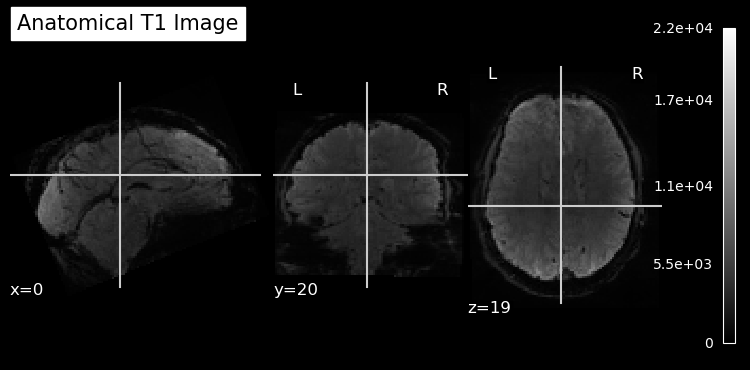

In [ ]:
img = nib.load(f"{hcp_data}/{subject_id}/unprocessed/3T/tfMRI_LANGUAGE_LR/{subject_id}_3T_tfMRI_LANGUAGE_LR.nii.gz")

mean_img = image.mean_img(img)

plotting.plot_anat(mean_img, title="Anatomical T1 Image")
plotting.show()

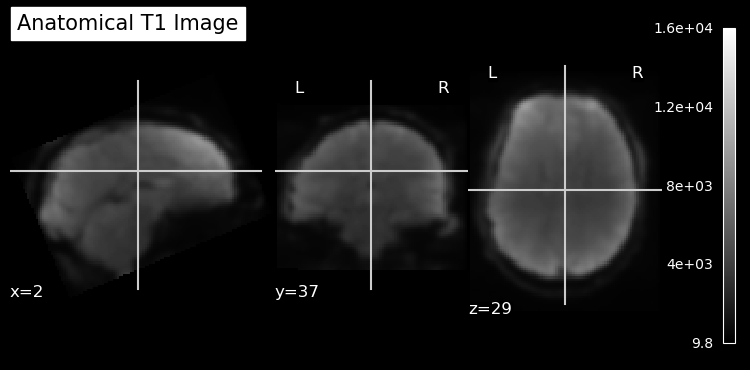

In [ ]:
mean_img = image.mean_img(imgs[2])

plotting.plot_anat(mean_img, title="Anatomical T1 Image")
plotting.show()

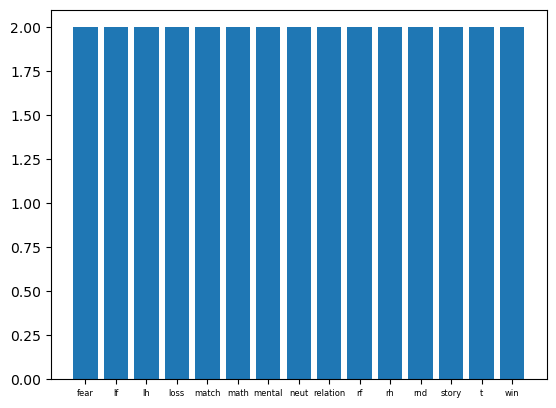

In [ ]:
plt.xticks(fontsize=6)
plt.bar(*np.unique(labels, return_counts=True))
plt.show()

## 4. 저장 결과와 시각화

### 산출물

`beta_map_datas`와 `labels`를 NumPy 배열로 바꿔 압축 NPZ로 저장한다.

| 키 | 내용 | 형태 |
|---|---|---|
| `data` | run·조건별 β-map 벡터 | `(30, 182453)` |
| `labels` | 각 행에 대응하는 조건명 | `(30,)` |

파일명은 `HCP_100206_data.npz`이며 피험자 폴더의 `preprocessed` 하위에 저장한다. 이 디렉터리는 실행 전에 준비해야 한다.

### 그림 읽는 법

위의 단면 그림은 원시 영상과 처리 영상의 **시간 평균 BOLD**를 보여준다. 기존 plotting 코드의 제목은 `Anatomical T1 Image`이지만, 실제 입력은 T1 구조영상이 아니다. 또한 서로 다른 run을 사용한 그림이므로 동일 run의 엄밀한 전후 비교보다는 영상 형태를 확인하는 용도로 읽는다.

마지막 막대그래프는 추출한 β-map의 조건별 개수다. 15개 조건에서 각각 2개씩, 총 30개가 만들어졌다. 이는 원시 자극의 제시 횟수가 아니라 GLM으로 추출한 map의 수다.

## 정리

이번 실습에서는 원시 HCP 영상과 이벤트 파일을 연결하고, 시간·움직임 보정과 평활화를 거쳐 조건별 β-map을 저장했다. 이후 분류 모델에 넣을 수 있는 벡터 형태까지 만드는 과정을 확인했다.

메모리 제약으로 공간 정합을 생략했고, 처리 영상을 누적 보관하는 구조도 남아 있다. 후속 분류 실험은 별도 제공 데이터로 진행했다. 직접 추출한 map을 추가 입력으로 사용했을 때의 결과는 HCP 분류 노트북에서 다룬다.
